# **Estudo sobre Acidentes e Incidentes Aérios em solo Brasileiro**

por Ítalo dos Santos Araujo Chaves

![Imagem de um avião](./images/aeronave-gol-25-anos-jpg)

## Breve Introdução
A aviação é o modal de transporte considerado o mais seguro, fica atrás apenas do elevador.  Cobrindo longas viagens em um curto espaço de tempo, tais aeronaves proveram diversas vantagens para o mundo, tanto comercial quanto a lazer. Infelizmente, como todo meio de transporte, as aeronaves possuem sua conta de tragédias.

## Sobre este estudo
Nesta apresentação, eu estarei utilizando dados abertos disponibilizados pela CENIPA - Centro de Investigação e Prevenção de Acidentes aeronáuticos. Tais arquivos conterão informações sobre ocorrências envolvendo aeronaves em Janeiro de 2007 a Abril de 2026. Você pode acessar dados mais atualizados visitando a página oficial de Dados Abertos Brasileiros, mas, caso deseje, poderá estar realizando o download dos datasets utilizados aqui através dos links de download abaixo.

Para este estudo, utilizarei de dois datasets da CENIPA:

**Ocorrencia.csv**: possui os dados sobre cada ocorrência registrada de em Janeiro de 2007 a Abril de 2026. Código da ocorrência, Data, Motivo da Ocorrência e Localização serão encontrados nesse conjunto de dados.

**Tipo_Ocorrencia.csv**: lista os tipos de ocorrências documentas pelo SIPAER.

**Aeronave.csv**: informações agrupadas sobre as aeronaves envolvidas nas ocorrências registradas no arquivo ocorrencia.csv. Aqui serão encontrados dados como: Modelo da Aeronave, Tipo de Aeronave, Fabricante, Quantidade de Fatalidades, dentre outras.

**Fator_Contribuinte.csv**: Detalhe os fatores contribuintes para ocorrência com os seguintes campos: Código de ocorrencia, Nome do fator, aspecto do fator, Fator condicionante e area. (Futuramente)

**Recomendacao.csv**: lista melhorias de segurança / procedimentos e ações para evitar novos acidentes/incidentes pelos fatores já conhecidos. (Futuramente)


## Perguntas a serem respondidas
Dentre outros insights gerados através deste estudo, quero responder as seguintes perguntas:

Quais são as maiores causas de ocorrências e, eventualmente, queda de aviões?

Como tem sido a progressão desses casos nos últimos anos? Tiveram menos ocorrências ou mais?

Quais os estados que mais possuem ocorrências registradas?

Qual tipo de aeronave possui mais problemas? Aviões, jatos, planadores?

Quais as fabricantes com maior número de defeitos registrados?

Será que durante o pouso é mais comum ter problemas do que durante a decolagem? Ou durante a viagem em si é mais frequente surgir defeitos?

Viagens comerciais regulares tendem a ter mais problemas do que voos fretados?

Quantos incidentes com fatalidades (morte de passageiros e tripulação) temos registro nos últimos 10 anos?



### Importando Bibliotecas

In [118]:
from docutils.nodes import fully_normalize_name
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import random

### Leitura Conjunto de dados

In [119]:
ocorrencia = pd.read_csv(
    './dataset/ocorrencia.csv',
    encoding='latin1',
    sep=';'
)

tipo_ocorrencia = pd.read_csv(
    './dataset/tipo_ocorrencia.csv',
    encoding='latin1',
    sep=';'
)

aeronave = pd.read_csv(
    './dataset/aeronave.csv',
    encoding='latin1',
    sep=';'
)
# fator_contribuinte = pd.read_csv('./dataset/fator_contribuinte.csv', encoding='latin1', sep=';')
# recomendacao = pd.read_csv('./dataset/recomendacao.csv', encoding='latin1', sep=';')

## Limpeza de Dados

O primeiro processo deste estudo será realizar a limpeza e tratativa dos dados. Vamos inicialmente verificar como a tabela do arquivo "ocorrencia.csv" é apresentada.

In [120]:
ocorrencia.head(5)

,codigo_ocorrencia,codigo_ocorrencia1,codigo_ocorrencia2,codigo_ocorrencia3,codigo_ocorrencia4,ocorrencia_classificacao,ocorrencia_latitude,ocorrencia_longitude,ocorrencia_cidade,ocorrencia_uf,...,ocorrencia_dia,ocorrencia_hora,investigacao_aeronave_liberada,investigacao_status,divulgacao_relatorio_numero,divulgacao_relatorio_publicado,divulgacao_dia_publicacao,total_recomendacoes,total_aeronaves_envolvidas,ocorrencia_saida_pista
0,88808,88808,88808,88808,88808,INCIDENTE,-23.43555555555,-46.47305555555,GUARULHOS,SP,...,19/04/2026,04:00:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
1,88804,88804,88804,88804,88804,INCIDENTE,-23.43555555555,-46.47305555555,GUARULHOS,SP,...,23/04/2026,15:00:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
2,88794,88794,88794,88794,88794,INCIDENTE,-22.81,-43.25055555555,RIO DE JANEIRO,RJ,...,28/04/2026,18:36:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
3,88783,88783,88783,88783,88783,INCIDENTE,-22.81,-43.25055555555,RIO DE JANEIRO,RJ,...,30/04/2026,19:30:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
4,88769,88769,88769,88769,88769,INCIDENTE GRAVE,-12.90861111111,-38.3225,SALVADOR,BA,...,09/05/2026,19:15:00,SIM,ATIVA,A DEFINIR,NÃO,NaN,0,1,SIM


Ocorrencia.csv é um arquivo relativamente grande. Ele possui muitas linhas e colunas que concedem muitos detalhes a cerca da ocorrência registrada, contudo, não precisamos de todas elas para esse estudo. A fim de deixar a exibição mais apresentável e limpa, vamos eliminar algumas colunas que não precisaremos, como o numero do relatório, comando investigador e aerodromo.

In [121]:
tipo_ocorrencia.head(5)

,codigo_ocorrencia1,ocorrencia_tipo,taxonomia_tipo_icao
0,88808,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,SCF-NP
1,88804,OPERAÇÕES NO SOLO,[RAMP]
2,88794,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,SCF-NP
3,88783,COLISÃO COM AVE,BIRD
4,88769,EXCURSÃO DE PISTA,RE


Acima você pode verifica como o arquivo esta estruturado. Como mencionado no inicio deste, irá encontrar ocorrências datadas a partir de Janeiro de 2007 até abril de 2026.

Em seguida, quero descobrir como a linguagem Python está identificara cada coluna. Será que ele está trata o código da ocorrência como número inteiro ou string? O comando dtypes nos responderá.

In [122]:
ocorrencia.dtypes

codigo_ocorrencia                 int64
codigo_ocorrencia1                int64
codigo_ocorrencia2                int64
codigo_ocorrencia3                int64
codigo_ocorrencia4                int64
ocorrencia_classificacao            str
ocorrencia_latitude                 str
ocorrencia_longitude                str
ocorrencia_cidade                   str
ocorrencia_uf                       str
ocorrencia_pais                     str
ocorrencia_aerodromo                str
ocorrencia_dia                      str
ocorrencia_hora                     str
investigacao_aeronave_liberada      str
investigacao_status                 str
divulgacao_relatorio_numero         str
divulgacao_relatorio_publicado      str
divulgacao_dia_publicacao           str
total_recomendacoes               int64
total_aeronaves_envolvidas        int64
ocorrencia_saida_pista              str
dtype: object

Perceba que cada linha abaixo do comando dtypes representa uma coluna do conjunto de dados "ocorrencia.csv", totalizando 19 linhas. A sua direita, está a forma como a linguagem interpreta ela. codigo_ocorrencia está, de fato, sendo tratado como número inteiro (int64), enquanto campos como localidade, UF e classificação são executados como string, ou object, como visto acima.

O próximo passo é tratar os nomes das colunas que iremos trabalhar. Antes de mais nada, vamos exibir cada uma delas, usando o comando columns da biblioteca pandas.

In [123]:
tipo_ocorrencia.dtypes

codigo_ocorrencia1     int64
ocorrencia_tipo          str
taxonomia_tipo_icao      str
dtype: object

In [124]:
ocorrencia.columns

Index(['codigo_ocorrencia', 'codigo_ocorrencia1', 'codigo_ocorrencia2',
       'codigo_ocorrencia3', 'codigo_ocorrencia4', 'ocorrencia_classificacao',
       'ocorrencia_latitude', 'ocorrencia_longitude', 'ocorrencia_cidade',
       'ocorrencia_uf', 'ocorrencia_pais', 'ocorrencia_aerodromo',
       'ocorrencia_dia', 'ocorrencia_hora', 'investigacao_aeronave_liberada',
       'investigacao_status', 'divulgacao_relatorio_numero',
       'divulgacao_relatorio_publicado', 'divulgacao_dia_publicacao',
       'total_recomendacoes', 'total_aeronaves_envolvidas',
       'ocorrencia_saida_pista'],
      dtype='str')

In [125]:
tipo_ocorrencia.columns

Index(['codigo_ocorrencia1', 'ocorrencia_tipo', 'taxonomia_tipo_icao'],
      dtype='str')

In [126]:
analise = pd.merge(
    ocorrencia,
    tipo_ocorrencia,
    on='codigo_ocorrencia1',
    how='outer'
)

In [127]:
analise.drop(['codigo_ocorrencia1','codigo_ocorrencia2', 'codigo_ocorrencia3', 'codigo_ocorrencia4', 'ocorrencia_aerodromo',
              'ocorrencia_hora', 'ocorrencia_latitude', 'ocorrencia_longitude',
              'investigacao_aeronave_liberada', 'divulgacao_relatorio_publicado', 'divulgacao_dia_publicacao',
              'total_recomendacoes',
              'total_aeronaves_envolvidas', 'ocorrencia_saida_pista', 'divulgacao_relatorio_numero',
              'taxonomia_tipo_icao'], axis=1, inplace=True)

C:\Users\Italo\AppData\Local\Temp\ipykernel_9492\3917993970.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  analise.drop(['codigo_ocorrencia1','codigo_ocorrencia2', 'codigo_ocorrencia3', 'codigo_ocorrencia4', 'ocorrencia_aerodromo',


In [128]:
analise.rename(columns={
    'codigo_ocorrencia': 'Código de Ocorrência',
    'ocorrencia_tipo': 'Tipo de Ocorrência',
    'ocorrencia_classificacao': 'Classificação',
    'ocorrencia_cidade': 'Cidade',
    'ocorrencia_uf': 'UF',
    'ocorrencia_pais': 'País',
    'ocorrencia_dia': 'Dia da Ocorrência',
    'investigacao_status': 'Status da Investigação'
}, inplace=True)

analise['Contagem'] = 1

analise['Código de Ocorrência'].dropna(axis = 0, inplace = True)

C:\Users\Italo\AppData\Local\Temp\ipykernel_9492\2844319463.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  analise.rename(columns={
C:\Users\Italo\AppData\Local\Temp\ipykernel_9492\2844319463.py:14: Pandas4Warning: The inplace keyword in Series.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  analise['Código de Ocorrência'].dropna(axis = 0, inplace = True)


In [129]:
analise.head(10)

,Código de Ocorrência,Classificação,Cidade,UF,País,Dia da Ocorrência,Status da Investigação,Tipo de Ocorrência,Contagem
0,28256,ACIDENTE,MOGI GUAÇU,SP,BRASIL,07/01/2007,FINALIZADA,OPERAÇÃO A BAIXA ALTITUDE,1
1,28335,ACIDENTE,LONDRINA,PR,BRASIL,19/01/2007,FINALIZADA,VOO CONTROLADO CONTRA O TERRENO,1
2,28355,ACIDENTE,BOCAIÚVA,MG,BRASIL,18/01/2007,FINALIZADA,FALHA ESTRUTURAL,1
3,28375,ACIDENTE,APUCARANA,PR,BRASIL,26/01/2007,FINALIZADA,COLISÃO COM OBSTÁCULO DURANTE A DECOLAGEM E POUSO,1
4,28377,ACIDENTE,IMPERATRIZ,MA,BRASIL,27/01/2007,FINALIZADA,FALHA DO MOTOR EM VOO,1
5,28379,ACIDENTE,FORMOSA DO RIO PRETO,BA,BRASIL,31/01/2007,FINALIZADA,VOO CONTROLADO CONTRA O TERRENO,1
6,28381,ACIDENTE,CATANDUVA,SP,BRASIL,20/01/2007,FINALIZADA,INDETERMINADO,1
7,28395,ACIDENTE,CHAPADA DOS GUIMARÃES,MT,BRASIL,07/02/2007,FINALIZADA,FALHA ESTRUTURAL,1
8,28437,ACIDENTE,FERNANDO DE NORONHA,PE,BRASIL,16/02/2007,FINALIZADA,FALHA DO MOTOR EM VOO,1
9,28455,ACIDENTE,BALSAS,MA,BRASIL,23/02/2007,FINALIZADA,COLISÃO COM OBSTÁCULO DURANTE A DECOLAGEM E POUSO,1


## Visualização dos Dados

O dataframe **ocorrencia** foi limpo e teve colunas renomeadas para melhor apresentação. Agora vamos apresentar percepções - insigths em tornos dos dados contidos.

Vamos a primeira pergunta:

**Como é classificada uma ocorrência? Como se divide o total geral nessas categorias?**

Para responder, crei a variável **classe_ocorrencia**, que armazenará as informações deste conjunto de dados por classificação. A Coluna contagem será somada, retornando um gráfico com o total de ocorrências para cada classificação.

In [130]:
#Cores para serem usadas nos gráficos
colors = [['#0D47A1','#1565C0','#1976D2','#1E88E5','#2196F3'],
          ['#311B92','#512DA8','#673AB7','#9575CD','#B39DDB'],
          ['#1B5E20','#388E3C','#4CAF50','#81C784','#66BB6A'],
          ['#E65100','#EF6C00','#F57C00','#FB8C00','#FF9800'],
          ['#3E2723','#4E342E','#5D4037','#6D4C41','#795548'],
          ['#BF360C','#D84315','#E64A19','#F4511E','#FF5722'],
          ['#880E4F','#AD1457','#C2185B','#D81B60','#E91E63']
         ]

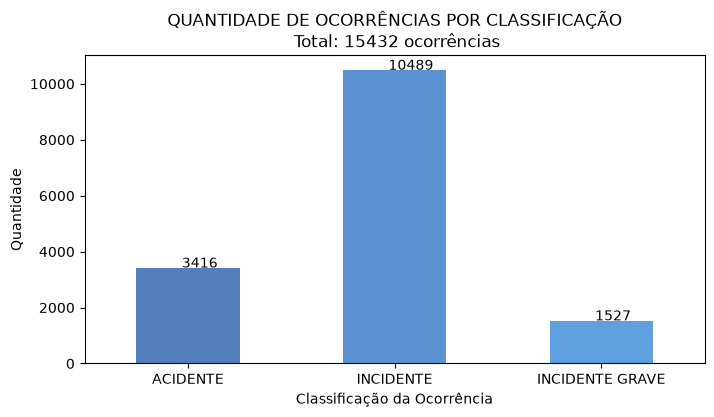

In [131]:
classe_ocorrencia = analise.groupby('Classificação')['Contagem'].sum().plot(kind='bar', figsize=(8,4), color=random.choice(colors), alpha=.7)

for p in classe_ocorrencia.patches:
    b=p.get_bbox()
    classe_ocorrencia.annotate("{:.0f}".format(b.y1 + b.y0), ((b.x0 + b.x1)/2 - 0.03, b.y1 + 15))

plt.xticks(rotation=0)
plt.xlabel('Classificação da Ocorrência')
plt.ylabel('Quantidade')
plt.title('QUANTIDADE DE OCORRÊNCIAS POR CLASSIFICAÇÃO\n Total: '+str(analise['Contagem'].sum())+' ocorrências')
plt.show()

Gráfico acima evidência que as ocorrências são dividas três classificações: Acidente, Incidente e Incidente Grave. Observe que este arquivo trata ocorrências envolvendo aeronaves de Janeiro de 2007 a Abril de 2026, últimos 19 anos. Estas aconteceram por falha humana, de procedimentos e/ou falha técnica.

Após classificação das ocorrências, reponderei:

**Quais os tipos de ocorrências catalogadas e a sua frequência nestes últimos anos?**

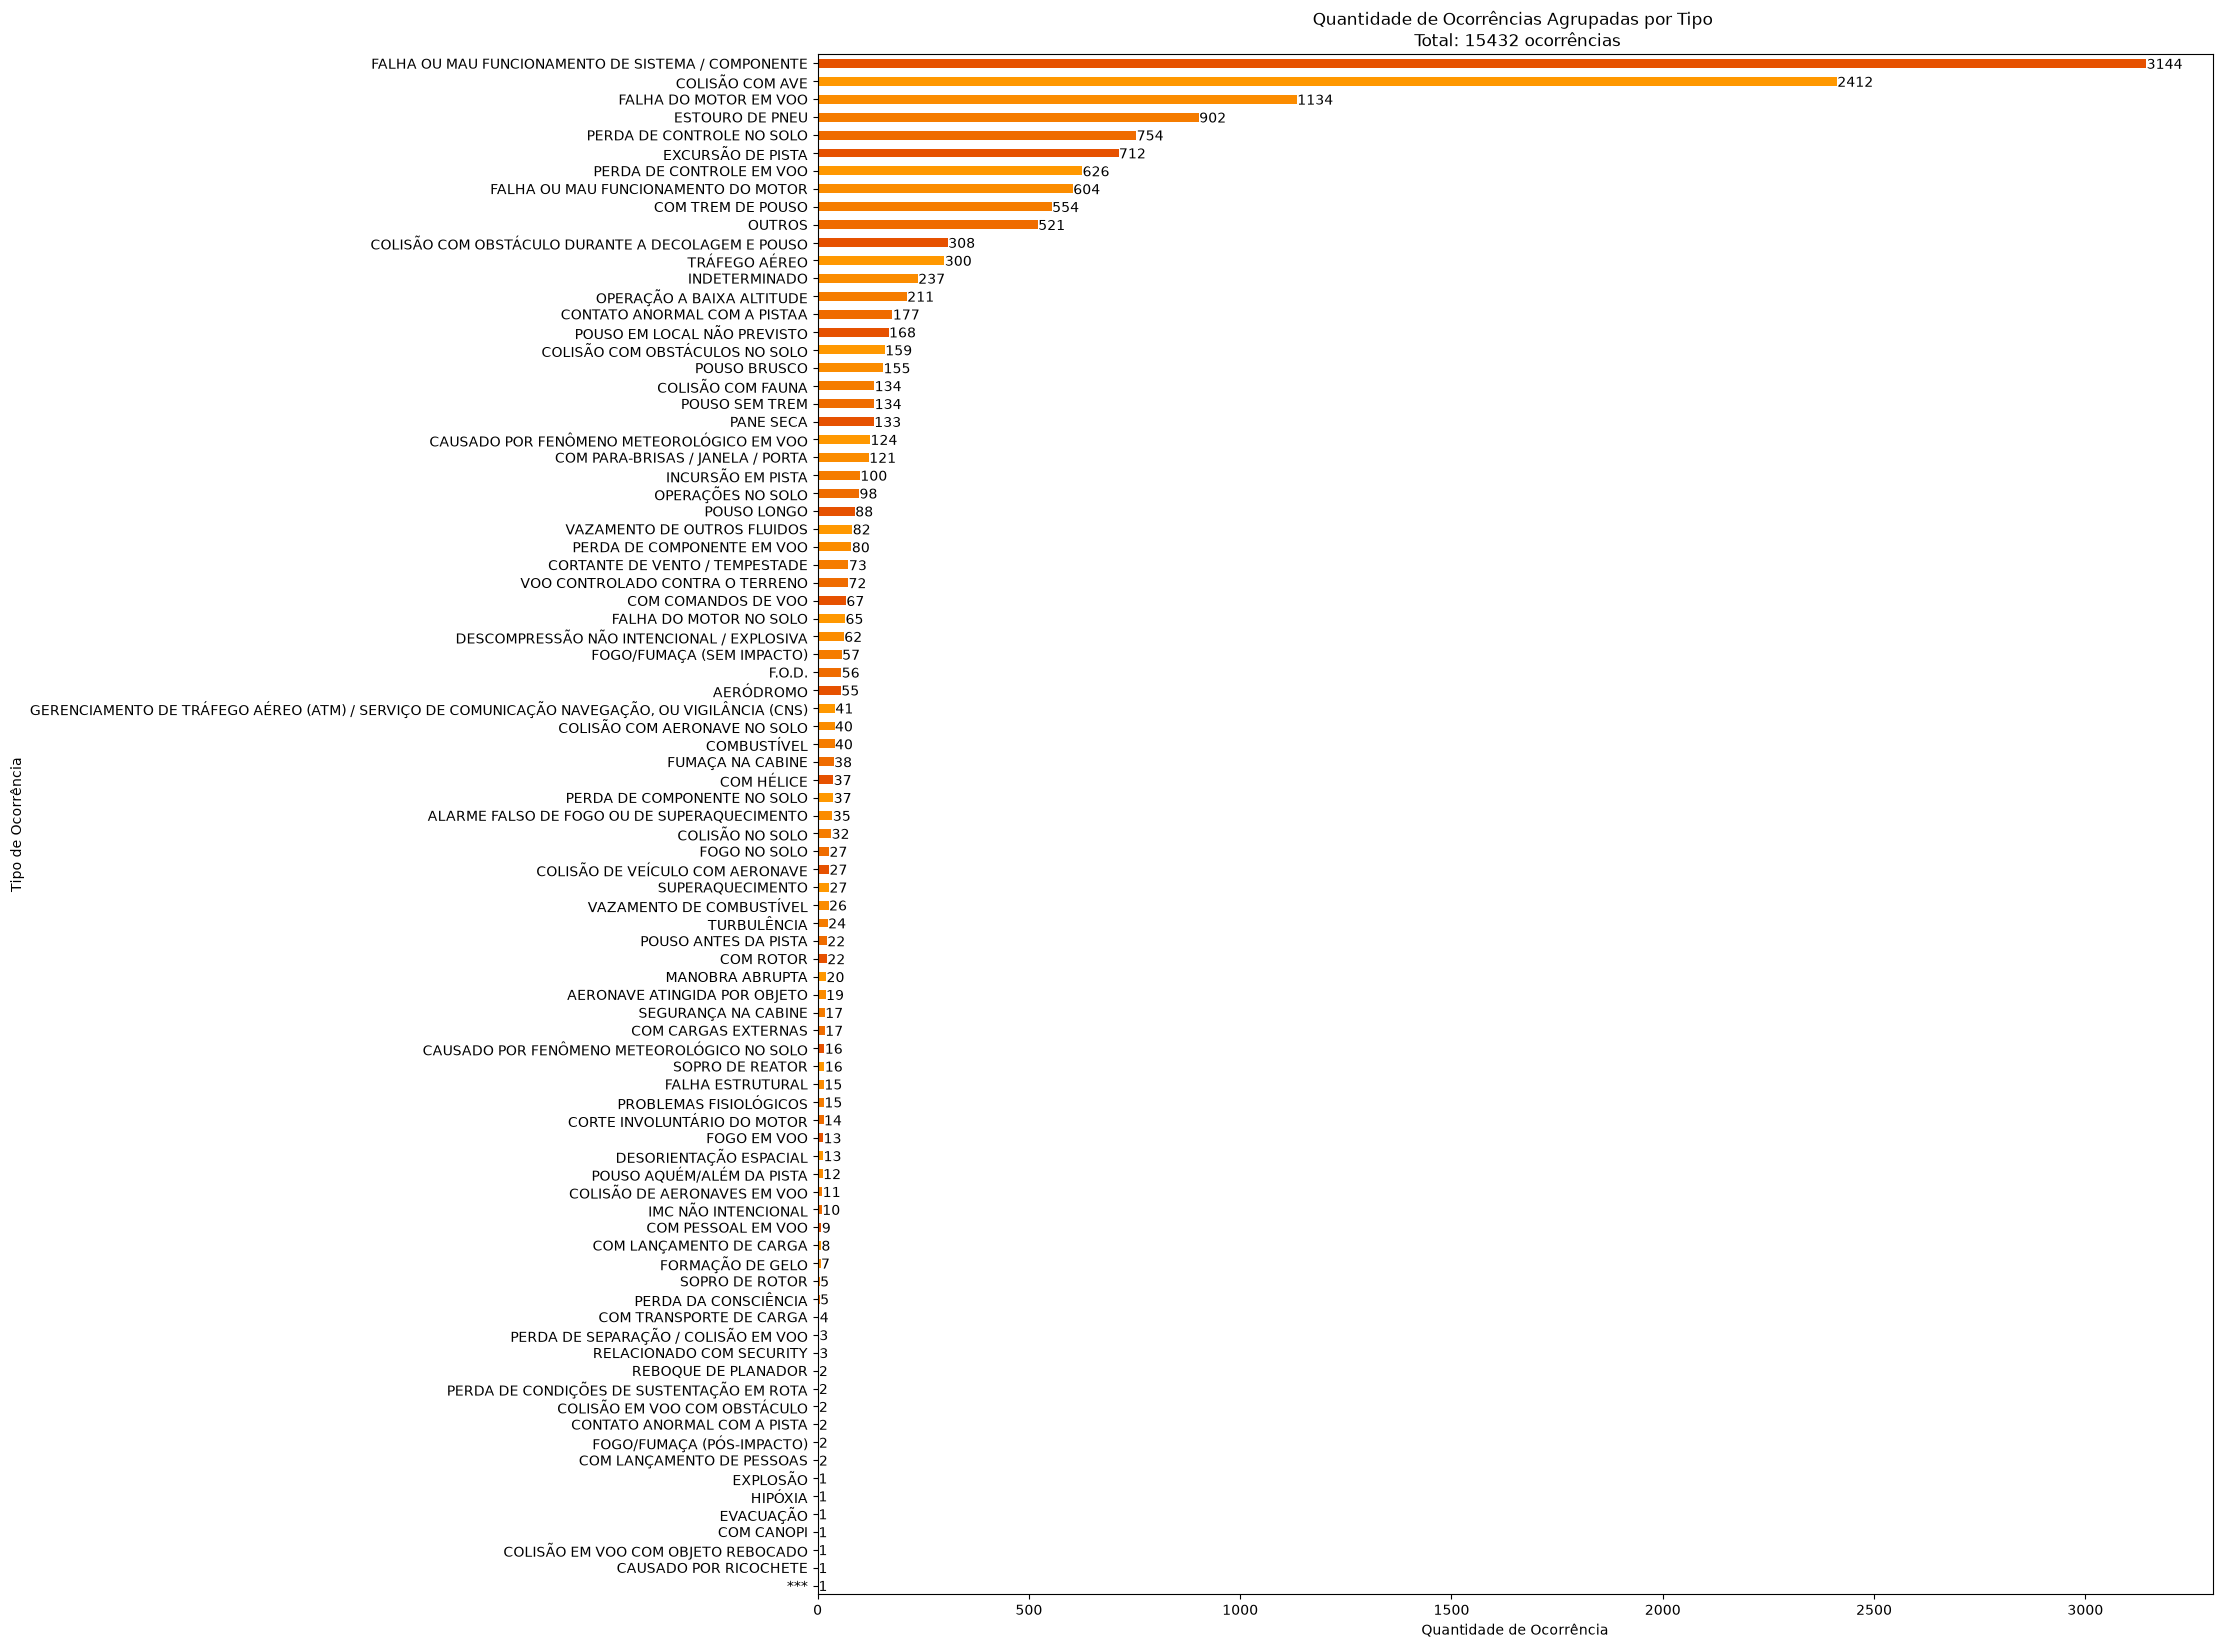

In [132]:
ax = analise.groupby('Tipo de Ocorrência')['Contagem'].sum().sort_values().plot(kind='barh', color=random.choice(colors), figsize=(18,20))

for p in ax.patches:
    b=p.get_bbox()
    ax.annotate("{:.0f}".format(b.x1 + b.x0), (p.get_x() + p.get_width() + 1, p.get_y() - 0.05))

plt.title('Quantidade de Ocorrências Agrupadas por Tipo \n Total: ' + str(analise['Contagem'].sum()) + ' ocorrências')
plt.ylabel('Tipo de Ocorrência')
plt.xlabel('Quantidade de Ocorrência')
plt.show()

As etapas para gerar o gráfico acima listando e quantificando quantidade de ocorrências por tipo, foi necessário agrupar dois dataframes, **ocorrencia** e **tipo_ocorrencia**, somando a quantidade de por cada tipo listado e relacionado de muitos para 1.
De acordo com a percepção do plot acima, as maiores causas de ocorrências são "falha ou mau funcionamento de sistema / componente" 3144 de 15432 ocorrências. Embora tais causas nos remetam a falha humana na operação, não podemos levar isto como uma regra. Uma perda de controle em vôo pode dever-se desde incompetência técnica até falha em dispositivos como o radar. Todavia, a escala destes três principais motivos é uma causa a se preocupar.

Vamos responder a próxima pergunta:

**Como tem sido a progressão desses últimos anos? Tiveram menos ocorrências ou mais?**

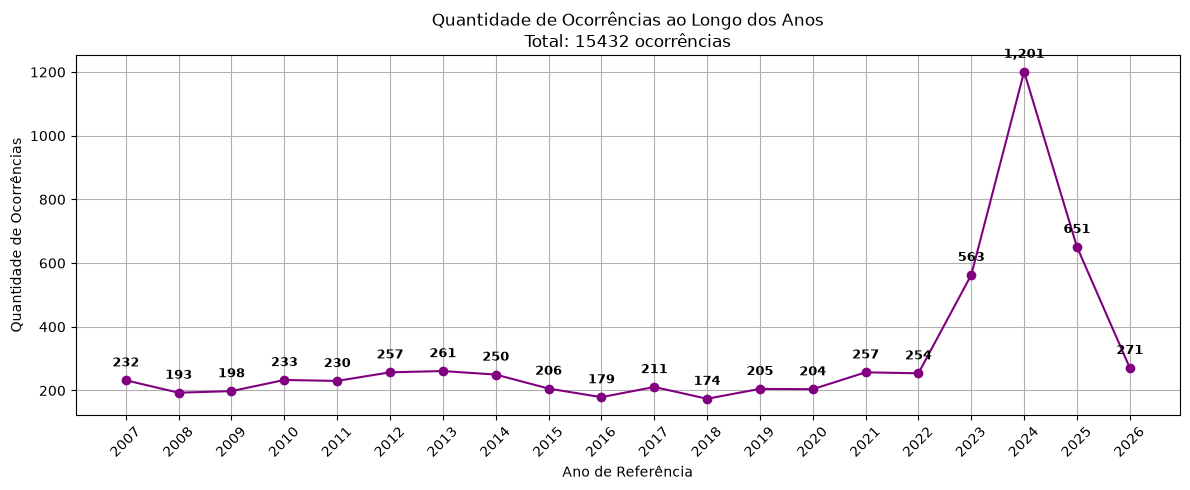

In [133]:
plotagem_data = analise.copy()

# Converter para datetime
plotagem_data['Dia da Ocorrência'] = pd.to_datetime(
    plotagem_data['Dia da Ocorrência'],
    errors='coerce'
)

# Extrair ano
plotagem_data['Ano'] = plotagem_data['Dia da Ocorrência'].dt.year

# Agrupar por ano
dados_ano = plotagem_data.groupby('Ano')['Contagem'].sum()

# Criar gráfico
fig, ax = plt.subplots(figsize=(12, 5))

dados_ano.plot(
    kind='line',
    marker='o',
    color='purple',
    grid=True,
    ax=ax
)

# Inserir quantidade de ocorrências em cada ponto
for x, y in zip(dados_ano.index, dados_ano.values):
    ax.annotate(
        f'{y:,.0f}',
        (x, y),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )

plt.title(
    'Quantidade de Ocorrências ao Longo dos Anos\n'
    + 'Total: '
    + str(analise['Contagem'].sum())
    + ' ocorrências'
)

plt.ylabel('Quantidade de Ocorrências')
plt.xlabel('Ano de Referência')
plt.xticks(dados_ano.index, rotation=45)

plt.tight_layout()
plt.show()

O período avaliado neste trabalho de análise de dados compreende 2007 - 2026, e neste tempo analisado, saimos de 205 ocorrências em 2019, onde se inicia um aumento leve para 257 ocorrências em 2021, mas entre 2024 a 2025 o número destes eventos foi isano, chegando em 2024 ao pico de 1201 ocorrências. A progressão de ocorrências aéres nos últimos anos tem crescido assustadoramente. Enquanto em 2008 tivemos menos que 198 ocorrências.

**E quanto aos estados? Quais foram os que mais registraram ocorrências?**

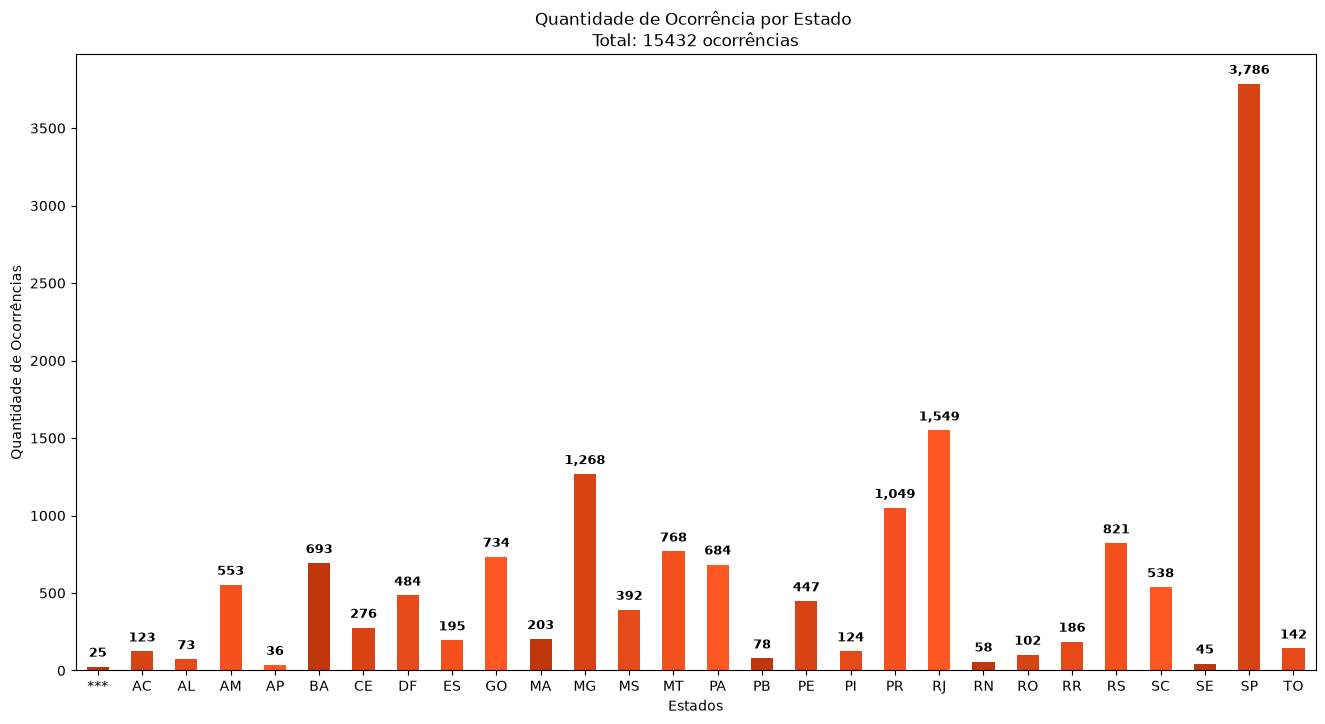

In [134]:
ax_estado = analise.groupby('UF')['Contagem'].sum().plot(kind='bar', color=random.choice(colors), figsize=(16,8))
# Adicionar valores no topo de cada barra
for barra in ax_estado.patches:
    valor = barra.get_height()

    ax_estado.annotate(
        f'{valor:,.0f}',
        (barra.get_x() + barra.get_width() / 2, valor),
        ha='center',
        va='bottom',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=9,
        fontweight='bold'
    )
plt.xlabel('Estados')
plt.ylabel('Quantidade de Ocorrências')
plt.title('Quantidade de Ocorrência por Estado \nTotal: ' + str(analise['Contagem'].sum()) + ' ocorrências')
plt.xticks(rotation=0)
plt.show()

Unidade Federativa de SP - São Paulo detém a maior incidência de ocorrências. Vale um questionamento sobre a modalidade de vôos no estado que gere essa quantidade de eventos, aviação executiva ou de carreira.


## **Analisando o dataset de aeronaves**

Agora iremos partir para o segundo conjunto de dados deste estudo: o dataset de aeronaves. Este arquivo possui informações acerca dos veículos que estavam envolvidos nas ocorrências registradas dos últimos anos. Primeiro, realizarei a fase de limpeza dos dados (semelhante ao feito anteriormente), depois, irei trazer alguns Insights a partir da visualização dos dados. Vamos começar?


## **Limpeza dos Dados (Data Cleaning**

O arquivo "aeronave.csv" possui 20 colunas com informações sobre os aviões. Muitos desses dados não são de grande valia para esse estudo, como matricula da aeronave, seu código, peso máximo na decolagem e categoria de registro. Inicialmente, irei removê-los do DataFrame para melhor visualização, depois, converterei colunas indevidas com seu respectivo tipo de arquivo, seguido por processos como renomeação de colunas e eliminação de dados nulos.

Abaixo, apresento as primeiras linhas do arquivo.

In [135]:
aeronave.head()

,codigo_ocorrencia2,aeronave_matricula,aeronave_tipo_equipamento,aeronave_fabricante,aeronave_modelo,aeronave_tipo_icao,aeronave_motor_tipo,anv_motor_qtd,anv_motor_descricao_qtd,aeronave_pmd,aeronave_assentos,aeronave_ano_fabricacao,aeronave_pais_fabricante,aeronave_pais_registro,aeronave_voo_origem,aeronave_voo_destino,aeronave_fase_operacao,aeronave_tipo_operacao,aeronave_nivel_dano,aeronave_fatalidades_total
0,88808,CCBGU,AVIÃO,BOEING COMPANY,B787-9,B789,JATO,2,BIMOTOR,253000.0,0.0,2018.0,CHILE,CHILE,GOVERNADOR ANDRÉ FRANCO MONTORO,JOHN F. KENNEDY INTERNATIONAL AIRPORT,SUBIDA,REGULAR,NENHUM,0.0
1,88804,CCBEN,AVIÃO,AIRBUS S.A.S.,A321-211,A321,JATO,2,BIMOTOR,89000.0,0.0,0.0,CHILE,CHILE,AEROPORTO INTERNACIONAL DE SANTIAGO,GOVERNADOR ANDRÉ FRANCO MONTORO,ESTACIONAMENTO,REGULAR,LEVE,0.0
2,88794,N412MC,AVIÃO,BOEING COMPANY,747-400 SERIES,B744,JATO,2,BIMOTOR,397000.0,0.0,0.0,ESTADOS UNIDOS,ESTADOS UNIDOS,ANTONIO CARLOS JOBIM / GALEÃO,VIRACOPOS,TÁXI,REGULAR,NENHUM,0.0
3,88783,CCBAC,AVIÃO,AIRBUS S.A.S,A320-233,A323,JATO,2,BIMOTOR,242000.0,0.0,0.0,CHILE,CHILE,AEROPORTO INTERNACIONAL JORGE CHÁVEZ,ANTONIO CARLOS JOBIM / GALEÃO,POUSO,REGULAR,LEVE,0.0
4,88769,PSGFC,AVIÃO,BOEING COMPANY,737-8EH,B738,JATO,2,BIMOTOR,75214.0,8.0,2007.0,BRASIL,BRASIL,GOVERNADOR ANDRÉ FRANCO MONTORO,DEPUTADO LUÍS EDUARDO MAGALHÃES,POUSO,REGULAR,NENHUM,0.0


A seguir eu retiro as colunas que não me interessam para este projeto. Perceba no bloco abaixo como fica a tabela sem esses dados.



In [136]:
aeronave.drop(['aeronave_tipo_icao','aeronave_pmd','aeronave_voo_origem','aeronave_voo_destino',
               'anv_motor_descricao_qtd','aeronave_pais_fabricante'], axis = 1, inplace=True)
aeronave.head(5)

C:\Users\Italo\AppData\Local\Temp\ipykernel_9492\2701749349.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  aeronave.drop(['aeronave_tipo_icao','aeronave_pmd','aeronave_voo_origem','aeronave_voo_destino',


,codigo_ocorrencia2,aeronave_matricula,aeronave_tipo_equipamento,aeronave_fabricante,aeronave_modelo,aeronave_motor_tipo,anv_motor_qtd,aeronave_assentos,aeronave_ano_fabricacao,aeronave_pais_registro,aeronave_fase_operacao,aeronave_tipo_operacao,aeronave_nivel_dano,aeronave_fatalidades_total
0,88808,CCBGU,AVIÃO,BOEING COMPANY,B787-9,JATO,2,0.0,2018.0,CHILE,SUBIDA,REGULAR,NENHUM,0.0
1,88804,CCBEN,AVIÃO,AIRBUS S.A.S.,A321-211,JATO,2,0.0,0.0,CHILE,ESTACIONAMENTO,REGULAR,LEVE,0.0
2,88794,N412MC,AVIÃO,BOEING COMPANY,747-400 SERIES,JATO,2,0.0,0.0,ESTADOS UNIDOS,TÁXI,REGULAR,NENHUM,0.0
3,88783,CCBAC,AVIÃO,AIRBUS S.A.S,A320-233,JATO,2,0.0,0.0,CHILE,POUSO,REGULAR,LEVE,0.0
4,88769,PSGFC,AVIÃO,BOEING COMPANY,737-8EH,JATO,2,8.0,2007.0,BRASIL,POUSO,REGULAR,NENHUM,0.0


Feita a exclusão, é hora de visualizar como o Python está tratando cada coluna.

In [137]:
aeronave.dtypes

codigo_ocorrencia2              int64
aeronave_matricula                str
aeronave_tipo_equipamento         str
aeronave_fabricante               str
aeronave_modelo                   str
aeronave_motor_tipo               str
anv_motor_qtd                     str
aeronave_assentos             float64
aeronave_ano_fabricacao       float64
aeronave_pais_registro            str
aeronave_fase_operacao            str
aeronave_tipo_operacao            str
aeronave_nivel_dano               str
aeronave_fatalidades_total    float64
dtype: object

Um primeiro ponto que me incomodou foi o fato dele estar tratando as colunas de quantidades de assentos, ano de fabricação, quantidade de motores e quantidade de fatalidades como valores flutuantes (float64), ou seja, com pontos decimais. Ora, não existe, por exemplo, aeronaves com dois motores e meio (2,5), tampouco morrem durante um acidente três pessoas e meia (3,5). Mais a frente, durante a fase de visualização dos dados, isso será um problema, portanto, vamos tratá-lo.

Primeiro eu crio duas funções: convert_na e convert_dtype. A primeira, irá procurar por valores nulos nas linhas das colunas especificadas no momento do chamado da função, e irá preenche-las com o numeral 0. Já a segunda função irá converter esse DataFrame atualizado para um tipo específico de formato (em nosso caso, numeros inteiros). Confira abaixo maiores detalhes de cada função.

In [138]:
def convert_dtype(dataframe, columns, dtype):
    for column in columns:
        dataframe[column] = pd.to_numeric(
            dataframe[column],
            errors='coerce'
        ).astype(dtype)


convert_dtype(aeronave, ['aeronave_assentos','aeronave_ano_fabricacao','aeronave_fatalidades_total'],'Int64')

Declaradas as funções e realizada as devidas alterações nas colunas, vamos ver como o Python interpretará tais dados agora.

In [139]:
aeronave.dtypes

codigo_ocorrencia2            int64
aeronave_matricula              str
aeronave_tipo_equipamento       str
aeronave_fabricante             str
aeronave_modelo                 str
aeronave_motor_tipo             str
anv_motor_qtd                   str
aeronave_assentos             Int64
aeronave_ano_fabricacao       Int64
aeronave_pais_registro          str
aeronave_fase_operacao          str
aeronave_tipo_operacao          str
aeronave_nivel_dano             str
aeronave_fatalidades_total    Int64
dtype: object

Como desejei, as colunas foram alteradas com sucesso de decimais para números inteiros.

O próximo passo é renomear todas as colunas restantes nesse DataFrame para podermos ter uma visualização melhor. Aproveito para converter todos os valores nulos para a sentença "NÃO IDENTIFICADO". Isso facilitará o entendimento. O último statement do código irá incluir uma nova coluna no DataFrame: CONTAGEM, a qual irei atribuir o valor único de 1 para poder realizar alguns cálculos com mais facilidade.

In [140]:
aeronave.columns = ['Código de Ocorrência','Matrícula','Equipamento','Fabricante',
                    'Modelo','Tipo de Motor','Quantidade de Motores','Quantidade de Assentos',
                    'Ano de Fabricação','País de Registro','Fase de Operação',
                    'Tipo de Operação','Nível de Danos','Número de Fatalidades']
aeronave = aeronave.apply(lambda x: x.replace('***','NÃO IDENTIFICADO'))
aeronave['Contagem'] = 1

Visualizar novo dataframe limpo e com colunas renomeadas

In [141]:
aeronave.head()

,Código de Ocorrência,Matrícula,Equipamento,Fabricante,Modelo,Tipo de Motor,Quantidade de Motores,Quantidade de Assentos,Ano de Fabricação,País de Registro,Fase de Operação,Tipo de Operação,Nível de Danos,Número de Fatalidades,Contagem
0,88808,CCBGU,AVIÃO,BOEING COMPANY,B787-9,JATO,2,0,2018,CHILE,SUBIDA,REGULAR,NENHUM,0,1
1,88804,CCBEN,AVIÃO,AIRBUS S.A.S.,A321-211,JATO,2,0,0,CHILE,ESTACIONAMENTO,REGULAR,LEVE,0,1
2,88794,N412MC,AVIÃO,BOEING COMPANY,747-400 SERIES,JATO,2,0,0,ESTADOS UNIDOS,TÁXI,REGULAR,NENHUM,0,1
3,88783,CCBAC,AVIÃO,AIRBUS S.A.S,A320-233,JATO,2,0,0,CHILE,POUSO,REGULAR,LEVE,0,1
4,88769,PSGFC,AVIÃO,BOEING COMPANY,737-8EH,JATO,2,8,2007,BRASIL,POUSO,REGULAR,NENHUM,0,1


Um fato me chamou a atenção neste arquivo de aeronaves: seu tamanho é maior que o arquivo de ocorrências. Levando em consideração que para cada aeronave há uma ocorrência, o que explicaria esse detalhe?

Para termos certeza de que os DataFrames ocorrencia.csv e aeronave.csv são diferentes, vamos conferir no código.

In [142]:
#Verificando se os dataframes são iguais
aeronave['Código de Ocorrência'].equals(analise['Código de Ocorrência'])

False

Sim, de fato são diferentes. A explicação para este fato é de que uma ocorrência que envolveu mais de uma aeronave terá o mesmo número de ocorrência para ambos. Vimos no gráfico acima que há casos onde aeronaves se chocaram em vôo. Para ambas foi aberta o mesmo número de ocorrências.

Vamos através do código abaixo, descobrir quantas ocorrências nós temos sob o mesmo código.

In [144]:
#Pegando linhas duplicadas no DataFrame
ocorrencias_duplicadas = aeronave[aeronave['Código de Ocorrência'].duplicated()].reset_index(drop=True)
ocorrencias_duplicadas.drop('Contagem', axis = 1, inplace = True)
print('Há ' + str(ocorrencias_duplicadas.shape[0]) + ' ocorrências duplicadas.')

Há 196 ocorrências duplicadas.


C:\Users\Italo\AppData\Local\Temp\ipykernel_9492\1411171299.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ocorrencias_duplicadas.drop('Contagem', axis = 1, inplace = True)


Vamos visualizar algumas das ocorrências de mesmo número

In [145]:
ocorrencias_duplicadas.head()

,Código de Ocorrência,Matrícula,Equipamento,Fabricante,Modelo,Tipo de Motor,Quantidade de Motores,Quantidade de Assentos,Ano de Fabricação,País de Registro,Fase de Operação,Tipo de Operação,Nível de Danos,Número de Fatalidades
0,88765,PSADE,AVIÃO,EMBRAER,ERJ 190-400,JATO,2,0,2025,BRASIL,DECOLAGEM,REGULAR,NENHUM,0
1,88761,PRWSB,AVIÃO,LEARJET,45 (LEARJET 40),JATO,2,9,2003,BRASIL,APROXIMAÇÃO FINAL,PRIVADA,NENHUM,0
2,88736,PSCBC,AVIÃO,EMBRAER,EMB-810C,NaN,2,0,0,BRASIL,APROXIMAÇÃO FINAL,PRIVADA,NENHUM,0
3,88733,PUMCL,ULTRALEVE,JEFFERSON A. M. CAMPELO,VIMANA R-12,PISTÃO,1,2,2003,BRASIL,APROXIMAÇÃO FINAL,EXPERIMENTAL,NENHUM,0
4,88733,PUMNM,ULTRALEVE,TECNAM CONSTRUZIONI AERONAUTICHE,P2008,PISTÃO,1,2,2011,BRASIL,APROXIMAÇÃO FINAL,EXPERIMENTAL,NENHUM,0


## **Visualização dos Dados**

Agora que tratamos e limpamos nosso dataset, é hora de visualizarmos os dados. Em nosso conjunto, existe a informação sobre o tipo de motor que a aeronave utiliza, sendo assim, a primeira pergunta que desejo responder é:

**Qual tipo de motor mais gerou ocorrências nos últimos 10 anos?**

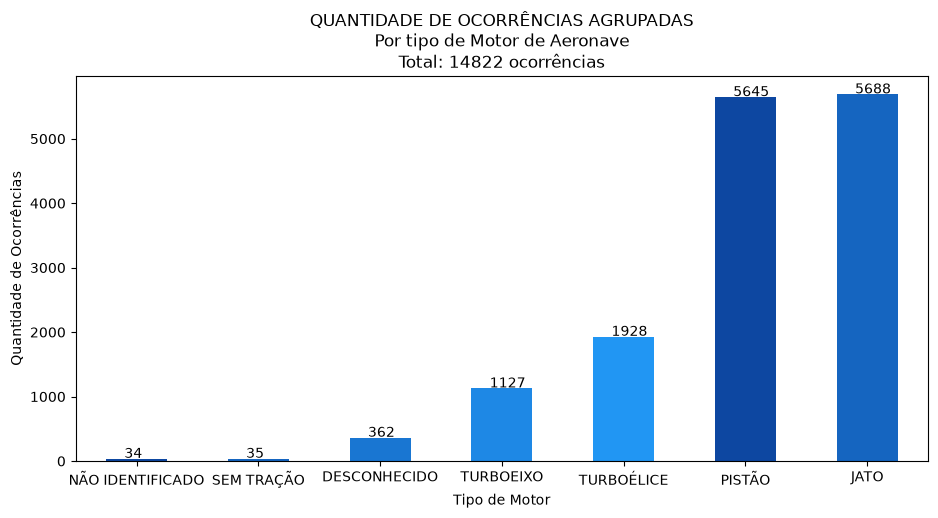

In [147]:
ax = aeronave.groupby('Tipo de Motor')['Contagem'].sum().sort_values().plot(kind='bar', color=random.choice(colors), figsize=(11,5))

for p in ax.patches:
    b=p.get_bbox()
    ax.annotate("{:.0f}".format(b.y1 + b.y0), ((b.x0 + b.x1)/2 - 0.1, b.y1 + 15))

plt.title('QUANTIDADE DE OCORRÊNCIAS AGRUPADAS\nPor tipo de Motor de Aeronave\nTotal: '+str(aeronave['Contagem'].sum())+' ocorrências')
plt.ylabel('Quantidade de Ocorrências')
plt.xticks(rotation=0)
plt.show()

Os motores a pistão reinam com as maiores quantidades de ocorrências geradas. Esse motor é um dos mais antigos (e até usados) motores de aeronave no mundo, muito comum em aviões monomotores. Além do baixo custo, eles são semelhantes aos motores de carro, mas tratados com os padrões de qualidade e confiança da aeronáutica, funcionando muito bem em baixar altitudes.

O segundo e terceiro lugar ficaram para os motores de Turboeixo e Turboélice. Assim como o motor de pistão, o Turboélice é caracterizado pela hélice que fica a frente do avião, utilizando a famosa Lei da Ação e Reação para movimentar a aeronave, contudo, sua diferença está em utilizar pequenos jatos para realizar tal funcionamento.

Próxima pergunta:
**Será que ocorrências envolvendo aviões aparecem em menor frequência do que para helicópter e outras aeronaves?**

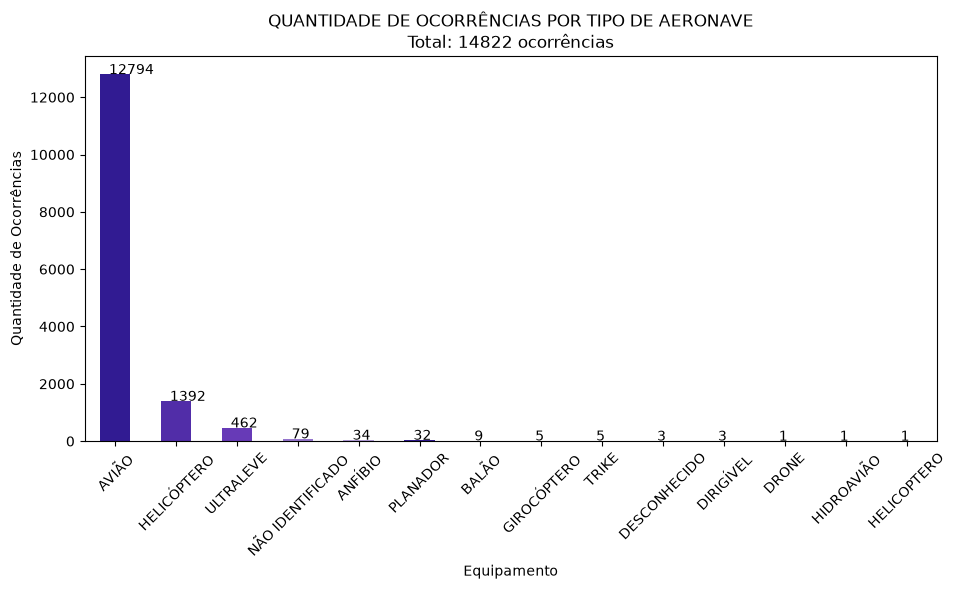

In [148]:
ax = aeronave.groupby('Equipamento')['Contagem'].sum().sort_values(ascending = False).plot(kind='bar', figsize=(11,5), color=random.choice(colors))

for p in ax.patches:
    b=p.get_bbox()
    ax.annotate("{:.0f}".format(b.y1 + b.y0), ((b.x0 + b.x1)/2 - 0.1, b.y1 + 15))

plt.title('QUANTIDADE DE OCORRÊNCIAS POR TIPO DE AERONAVE\nTotal: ' + str(aeronave['Contagem'].sum()) + ' ocorrências')
plt.ylabel('Quantidade de Ocorrências')
plt.xticks(rotation=45)
plt.show()

Definitivamente, ocorrências envolvendo aviões surgem com muito mais frequência do que para helicópteros. Na verdade, a quantidade total de ocorrências de aviões é maior do que a soma de todos os outros tipos de aeronave. Até mesmo dirigíveis aparecem neste dataset!

Se temos tantas quantidades de ocorrências registradas nesses anos, **quais são as fabricantes que mais aparecem nos problemas relatados?**

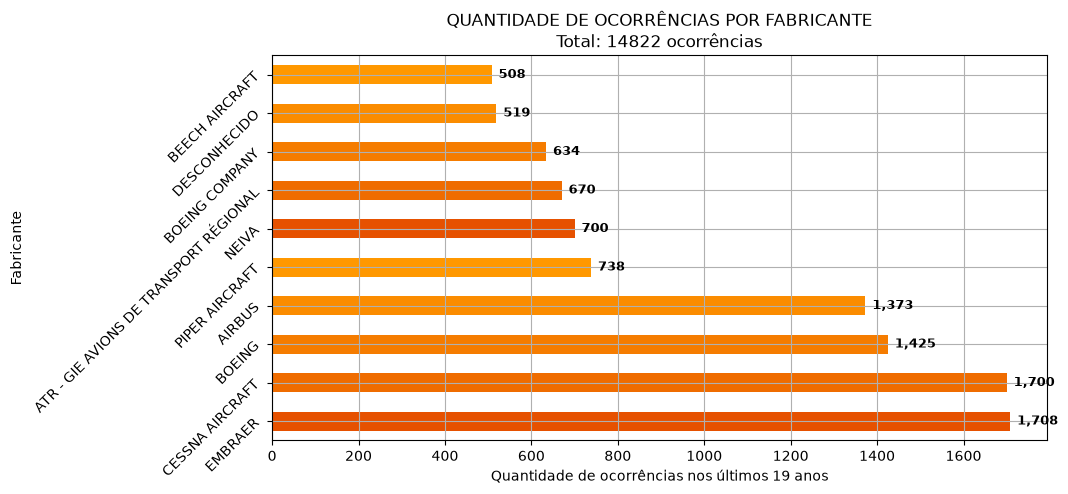

In [161]:
ocorrencias_fabricante = (aeronave.groupby('Fabricante')['Contagem'].sum().sort_values(ascending = False)
                          .head(10).plot(kind='barh', figsize=(10,5), color=random.choice(colors), grid=True))

for barra in ocorrencias_fabricante.patches:
    valor = barra.get_width()

    ocorrencias_fabricante.annotate(f'{valor:,.0f}',
        (valor,barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0), textcoords='offset points',ha='left',va='center',fontsize=9,fontweight='bold')

plt.title('QUANTIDADE DE OCORRÊNCIAS POR FABRICANTE\nTotal: ' + str(aeronave['Contagem'].sum()) + ' ocorrências')
plt.xlabel('Quantidade de ocorrências nos últimos 19 anos')
plt.yticks(rotation=45)
plt.show()

A fabricante brasileira Neiva Industria ocupa 19,6% das causas de ocorrências envolvendo aeronaves, seguida pela Cessna Aircraft e Piper Aircraft. A Neiva Industria Aeronáutica tem estado há 50 anos no mercado produzindo, principalmente, aviões de motores a pistão voltados para agricultura. Já a Cessna Aircraft é uma empresa americana, sediada no Kansas, que possui um inventário mais abrangente de aeronaves, produzindo desde monomotores a aviões a jato.

A quantidade de ocorrências para essas duas fabricantes mostra a diferença gritante em relação as outras. A Neiva Industria, por exemplo, possui uma diferença próxima de 150% em relação ao terceiro lugar: a Piper Aircraft. Tais indicadores seriam uma boa forma de reavaliar o processo de montagem, manutenção e qualidade de peças dessas fabricantes.

Um outro questionamento que podemos fazer é:

**Viagens comerciais regulares tendem a ter mais problemas do que voos fretados?**

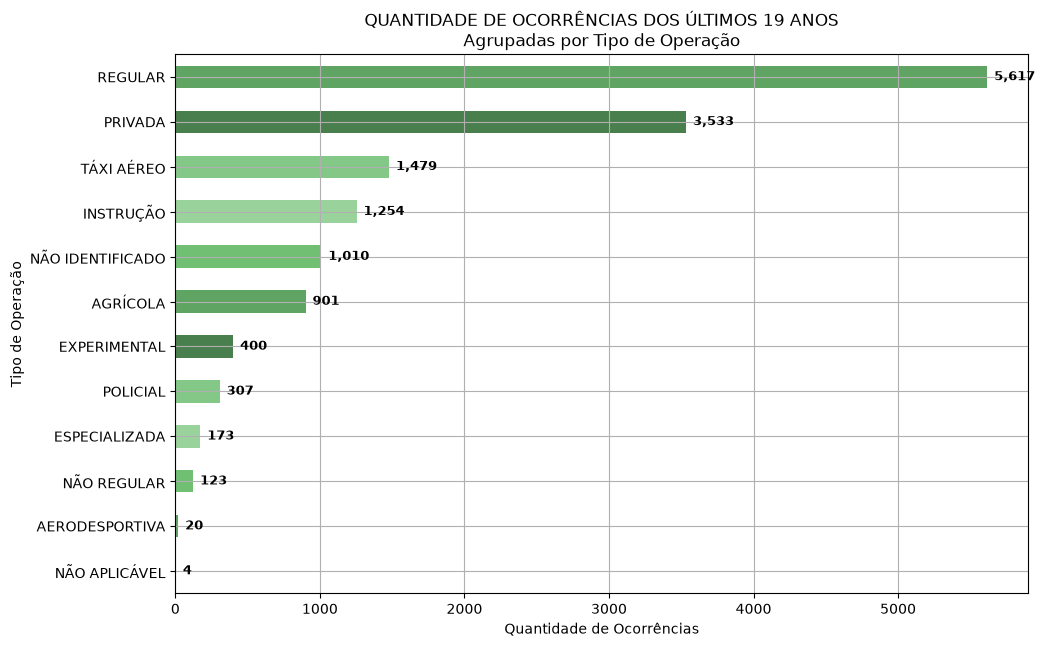

In [164]:
categoria_aviao = aeronave.groupby('Tipo de Operação')['Contagem'].sum().sort_values().plot(kind='barh', figsize=(11,7), color=random.choice(colors), alpha=.8, grid = True)

for barra in categoria_aviao.patches:
    valor = barra.get_width()

    categoria_aviao.annotate(f'{valor:,.0f}',
        (valor,barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0), textcoords='offset points',ha='left',va='center',fontsize=9,fontweight='bold')

plt.title('QUANTIDADE DE OCORRÊNCIAS DOS ÚLTIMOS 19 ANOS\nAgrupadas por Tipo de Operação')
plt.xlabel('Quantidade de Ocorrências')
plt.show()

Muitas pessoas tem medo de voar. Isso é fato, contudo, esses dados mostrados no gráfico acima mostram que esse medo pode ser diminuído. A esmagadora maioria de ocorrências registradas são atribuídas a aeronaves particulares, que podem ser desde monomotores e ultraleves até aviões particulares. O transporte Regular - aquele que companhias aéreas oferecem para o público em geral -, possui menos de 100 ocorrências nos últimos anos. Tais dados explicam o porquê da Neiva Industria ser uma das fabricantes que mais possuem ocorrência, já que a grande fatia desta escala é atribuida aos principais tipos de avião que ela produz.

Vamos agora olhar para o momento em que as ocorrências surgiram. Com isso, quero saber se é mais propício ocorrer um problema durante o pouso, decolagem ou outro momento da viagem.

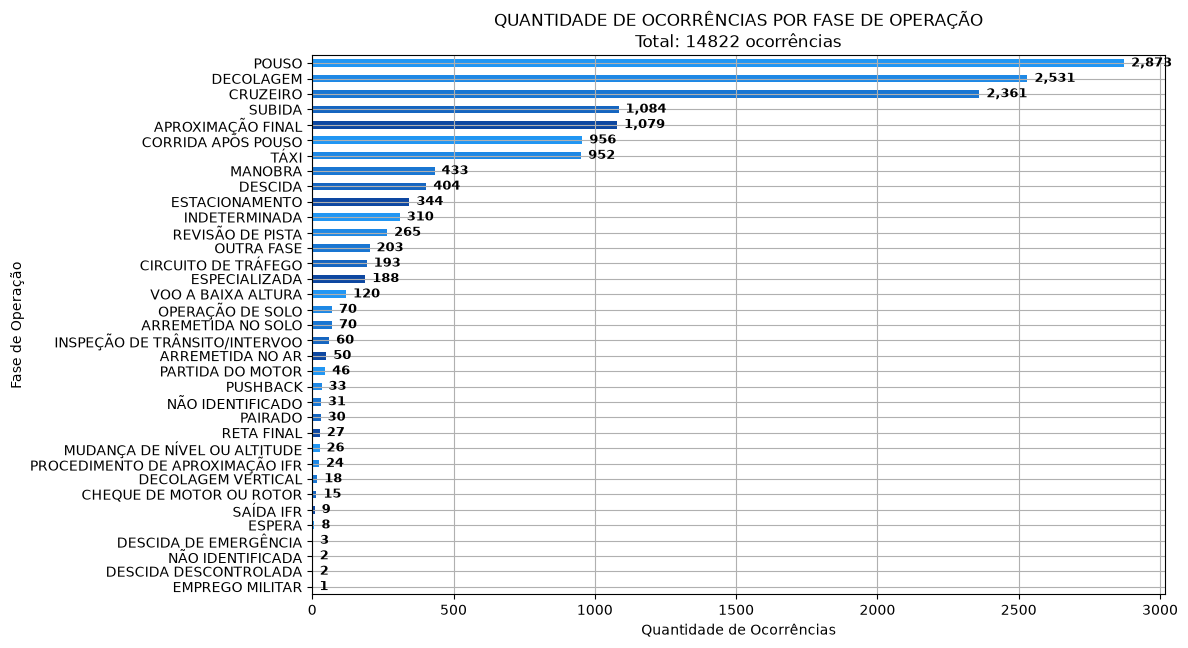

In [165]:
fase_de_operacao = aeronave.groupby('Fase de Operação')['Contagem'].sum().sort_values().plot(kind='barh', figsize=(11,7), color=random.choice(colors), grid = True)

for barra in fase_de_operacao.patches:
    valor = barra.get_width()

    fase_de_operacao.annotate(f'{valor:,.0f}',
        (valor,barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0), textcoords='offset points',ha='left',va='center',fontsize=9,fontweight='bold')

plt.title('QUANTIDADE DE OCORRÊNCIAS POR FASE DE OPERAÇÃO\nTotal: ' + str(aeronave['Contagem'].sum()) + ' ocorrências')
plt.xlabel('Quantidade de Ocorrências')
plt.show()

De fato, o momento do pouso é um dos mais importantes da viagem. Cerca de 2873 ocorrências, das mais de 14 mil registradas ocorreram nesta fase. Contudo, vale ressaltar que a decolagem está consideravelmente próxima ao pouso, fazendo dela uma operação delicada também. Já a fase de cruzeiro, que se encontra em terceira posição, é o momento da viagem em si, quando o avião está trafegando da origem ao destino.

Como já disse anteriormente, nem toda ocorrência gerada resulta em fatalidades e danos na aeronave. Uma ocorrência, como o nome já diz, se refere ao fato de que algum evento não previsto ocorreu.

Não obstante, esta é uma pergunta interessante a se responder. Afinal, **quais são os tipos de danos que podem ocorrer a uma aeronave? Qual a frequência?**

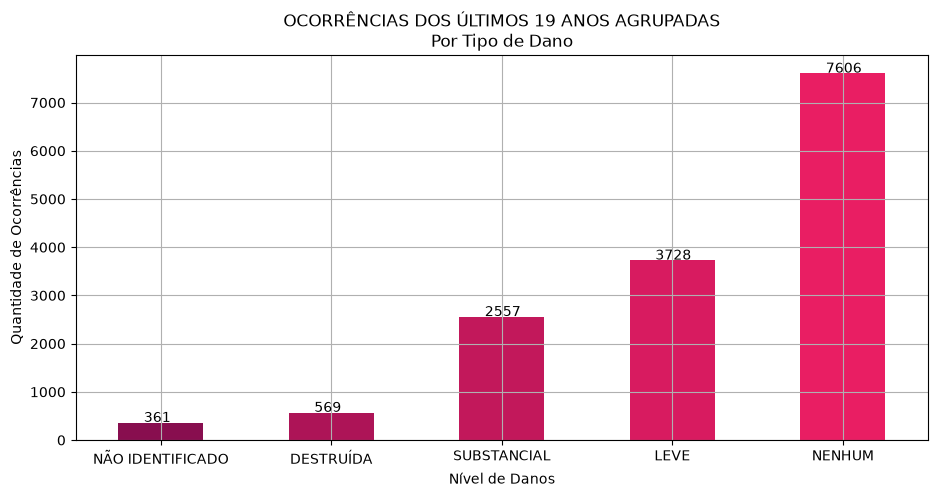

In [166]:
tipo_de_dano = aeronave.groupby('Nível de Danos')['Contagem'].sum().sort_values().plot(kind='bar', figsize=(11,5), color=random.choice(colors), grid = True)

for p in tipo_de_dano.patches:
    b=p.get_bbox()
    tipo_de_dano.annotate("{:.0f}".format(b.y1 + b.y0), ((b.x0 + b.x1)/2 - 0.1, b.y1 + 15))

plt.title('OCORRÊNCIAS DOS ÚLTIMOS 19 ANOS AGRUPADAS\nPor Tipo de Dano')
plt.ylabel('Quantidade de Ocorrências')
plt.xticks(rotation=0)
plt.show()

Danos substanciais são aqueles que danificaram significantemente a aeronave. Há casos em que a fuselagem foi danificada, uma asa, turbina, hélice, dentre outros. Este tipo é o que mais surgiu durante esses anos, seguido por danos em que a aeronave ficou totalmente destruída.

Por fim, quero saber em quantas ocorrências houveram fatalidades. **Para ter essa informação, agruparei os casos onde pessoas morreram por quantidade, a fim de saber não só quantas fatalidades houveram nesta última década, mas também a sua frequência.**

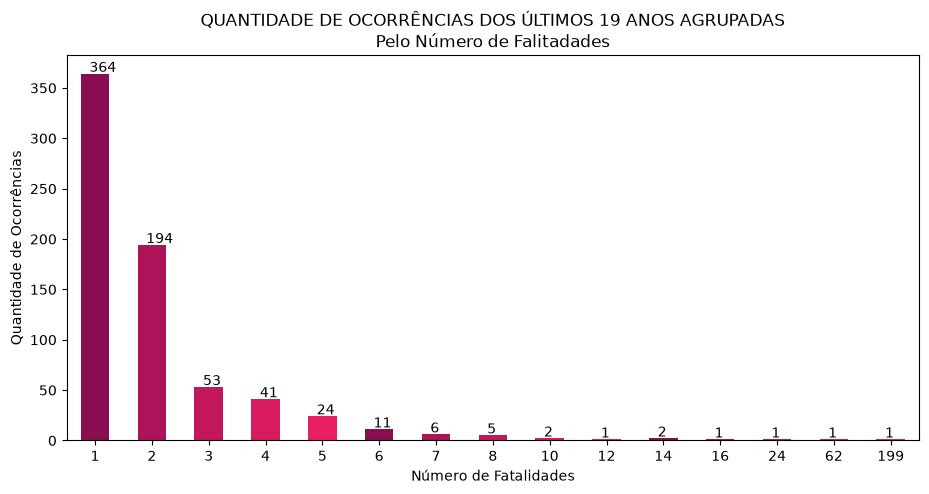

In [167]:
fatalidades_maior_que_zero = aeronave[aeronave['Número de Fatalidades'] > 0]
fatalidades = fatalidades_maior_que_zero.groupby('Número de Fatalidades')['Contagem'].sum().plot(kind='bar', figsize=(11,5), color=random.choice(colors))

for p in fatalidades.patches:
    b=p.get_bbox()
    fatalidades.annotate("{:.0f}".format(b.y1 + b.y0), ((b.x0 + b.x1)/2 - 0.1, b.y1 + 2))

plt.title('QUANTIDADE DE OCORRÊNCIAS DOS ÚLTIMOS 19 ANOS AGRUPADAS\nPelo Número de Falitadades')
plt.ylabel('Quantidade de Ocorrências')
plt.xticks(rotation=0)
plt.show()

Para esse gráfico, ignorei casos onde não houveram fatalidades, que felizmente, é a grande maioria. Os dados restantes geraram o gráfico acima, que mostra que a maior frequência de mortes é atribuída a apenas uma pessoa. Novamente, lembre-se que a maioria das ocorrências registradas são de aviões a pistão, aeronaves estas presentes na linha de produção da fabricante com mais ocorrências: a Neiva Industria. Aeronaves monomotores e ultraleves possuem uma quantidade de assentos bem limitada - cerca de um ou dois. Tais quantidades são justamente encontradas nas duas primeiras posições do gráfico.

Mas, um caso me chamaram a atenção. Ao final do gráfico, é possível visualizar que há um caso onde morreram 199 pessoas.

Abaixo, você pode conferir as duas linhas onde essas ocorrências se encontram na tabela.

In [169]:
piores_acidentes = aeronave[aeronave['Número de Fatalidades'] > 10]
piores_acidentes

,Código de Ocorrência,Matrícula,Equipamento,Fabricante,Modelo,Tipo de Motor,Quantidade de Motores,Quantidade de Assentos,Ano de Fabricação,País de Registro,Fase de Operação,Tipo de Operação,Nível de Danos,Número de Fatalidades,Contagem
3106,85259,PSVPB,AVIÃO,ATR - GIE AVIONS DE TRANSPORT RÉGIONAL.,ATR 72-212A (500),TURBOÉLICE,2,73,2010,BRASIL,CRUZEIRO,REGULAR,DESTRUÍDA,62,1
5496,82358,PTMEE,AVIÃO,CESSNA AIRCRAFT,208B,TURBOÉLICE,1,11,1993,BRASIL,DECOLAGEM,TÁXI AÉREO,DESTRUÍDA,12,1
5811,82005,PTSOG,AVIÃO,EMBRAER,EMB-110P1,TURBOÉLICE,2,20,1991,BRASIL,POUSO,TÁXI AÉREO,SUBSTANCIAL,14,1
12855,44796,PRNOB,AVIÃO,AIRCRAFT INDUSTRIES,L410UVP-E20,TURBOÉLICE,2,21,2010,BRASIL,DECOLAGEM,REGULAR,DESTRUÍDA,16,1
14008,37577,PRMOZ,AVIÃO,RAYTHEON AIRCRAFT,B300,TURBOÉLICE,2,11,1999,BRASIL,APROXIMAÇÃO FINAL,PRIVADA,DESTRUÍDA,14,1
14397,34935,PTSEA,AVIÃO,EMBRAER,EMB-110P1,TURBOÉLICE,2,21,1981,BRASIL,CRUZEIRO,TÁXI AÉREO,DESTRUÍDA,24,1
14769,29859,PRMBK,AVIÃO,AIRBUS INDUSTRIE,A320-233,JATO,2,185,1998,BRASIL,POUSO,REGULAR,DESTRUÍDA,199,1


Após uma pesquisa, lembrei-me de qual caso foi este. Trata-se do desastre envolvendo um Airbus A-320 no ano de 2007 em São Paulo, quando este tentou, sem sucesso, pousar na pista principal do aeroporto de Congonhas. Sob chuva, a aeronave ultrapassou os limites do aeroporto, atravessou a avenida Washington Luiz - chegando a tocar em um táxi durante o trajeto - e acabou se chocando contra um prédio da TAM Express. Você pode conferir maiores informações sobre esse trágico acidente que matou 199 pessoas <http://noticias.uol.com.br/ultnot/especial/acidentecongonhas/ultnot/2007/07/27/ult5258u401.jhtm>

In [172]:
#Linha da ocorrência gerada devido ao acidente do Airbus A-320
analise[analise['Código de Ocorrência'] == 29859]

,Código de Ocorrência,Classificação,Cidade,UF,País,Dia da Ocorrência,Status da Investigação,Tipo de Ocorrência,Contagem
52,29859,ACIDENTE,SÃO PAULO,SP,BRASIL,17/07/2007,FINALIZADA,PERDA DE CONTROLE NO SOLO,1



## **Conclusão**

Aviões e aeronaves não estão insentas de sofrerem acidentes e problemas. A história tem registros de casos onde centenas de pessoas morreram e milhares de ocorrências foram geradas. Não obstante, vale lembrar que, embora o impacto gerado por uma queda de avião seja grande, sua probabilidade de ocorrer ainda é pequena.

Mas, vamos levar em consideração outros meios de transporte, como o carro e moto. Apenas no Brasil em 2013, 41 mil pessoas morreram devido a acidentes de trânsito, fazendo do Brasil o país com maior número de mortes no trânsito da América do Sul. Já no mundo, tais acidentes são responsáveis por mais de 1,25 milhão de fatalidades, tendo uma frequência maior em países como China, EUA e Índia.

Sim, de fato aviões não são indestrutíveis ou absolutamente seguros, mas, mesmo em meio ao cenário atual, é uma das formas mais seguras de viajar.

Observação: Não é mencionado o vôo Gol 1907 devido a janela de tempo analisado (2007 - 2026) neste trabalho, o acidente 29 de Setembro de 2006 quando ocorreu uma colisão com o um avião Embraer Lagacy vitimando 154 pessoas.


## **Referências**
https://dados.gov.br/dados/conjuntos-dados/ocorrencias-aeronauticas-da-aviacao-civil-brasileira
https://nacoesunidas.org/oms-brasil-e-o-pais-com-maior-numero-de-mortes-de-transito-por-habitante-da-america-do-sul/
http://www.un.org/apps/news/story.asp?NewsID=52300#.ViZ1yNKrSM-
http://g1.globo.com/mato-grosso/noticia/2016/09/acidente-com-aviao-da-gol-que-matou-154-pessoas-completa-10-anos.html
http://noticias.uol.com.br/ultnot/especial/acidentecongonhas/ultnot/2007/07/27/ult5258u401.jhtm
http://globoesporte.globo.com/sc/futebol/times/chapecoense/acidente/